# Descriptores del módulo clásico por clase (T35)

Cada imagen se resume en unos pocos números (`src/features.py`). Este notebook muestra, **solo con el conjunto de
entrenamiento** de la ubicación 1, qué descriptor separa cada clase. Las reglas y sus umbrales (T40, T41) salen de
este análisis. Los descriptores se calculan con `python -m src.build_features`.

| Descriptor | Qué mide | Clase que debería delatar |
|---|---|---|
| `lap_var` | Varianza del Laplaciano (nitidez) | Desenfocada y tapada (bajo) |
| `gray_std`, `entropy` | Contraste y variedad de tonos | Tapada (bajo) |
| `sat_mean`, `hue_std`, `skin_ratio` | Color en HSV | Tapada (un solo color, mano) |
| `orb_matches`, `orb_inliers` | Coincidencias ORB con las 8 referencias normales | Girada y cualquier sabotaje (bajo) |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

ORDER = ["normal", "desenfocada", "girada", "tapada"]
descriptors = pd.read_csv(ROOT / "results" / "clasico" / "descriptores_ubicacion1.csv")
train = descriptors[descriptors["set"] == "train"]
train["label"].value_counts().reindex(ORDER)

label
normal         1120
desenfocada     356
girada           84
tapada          370
Name: count, dtype: int64

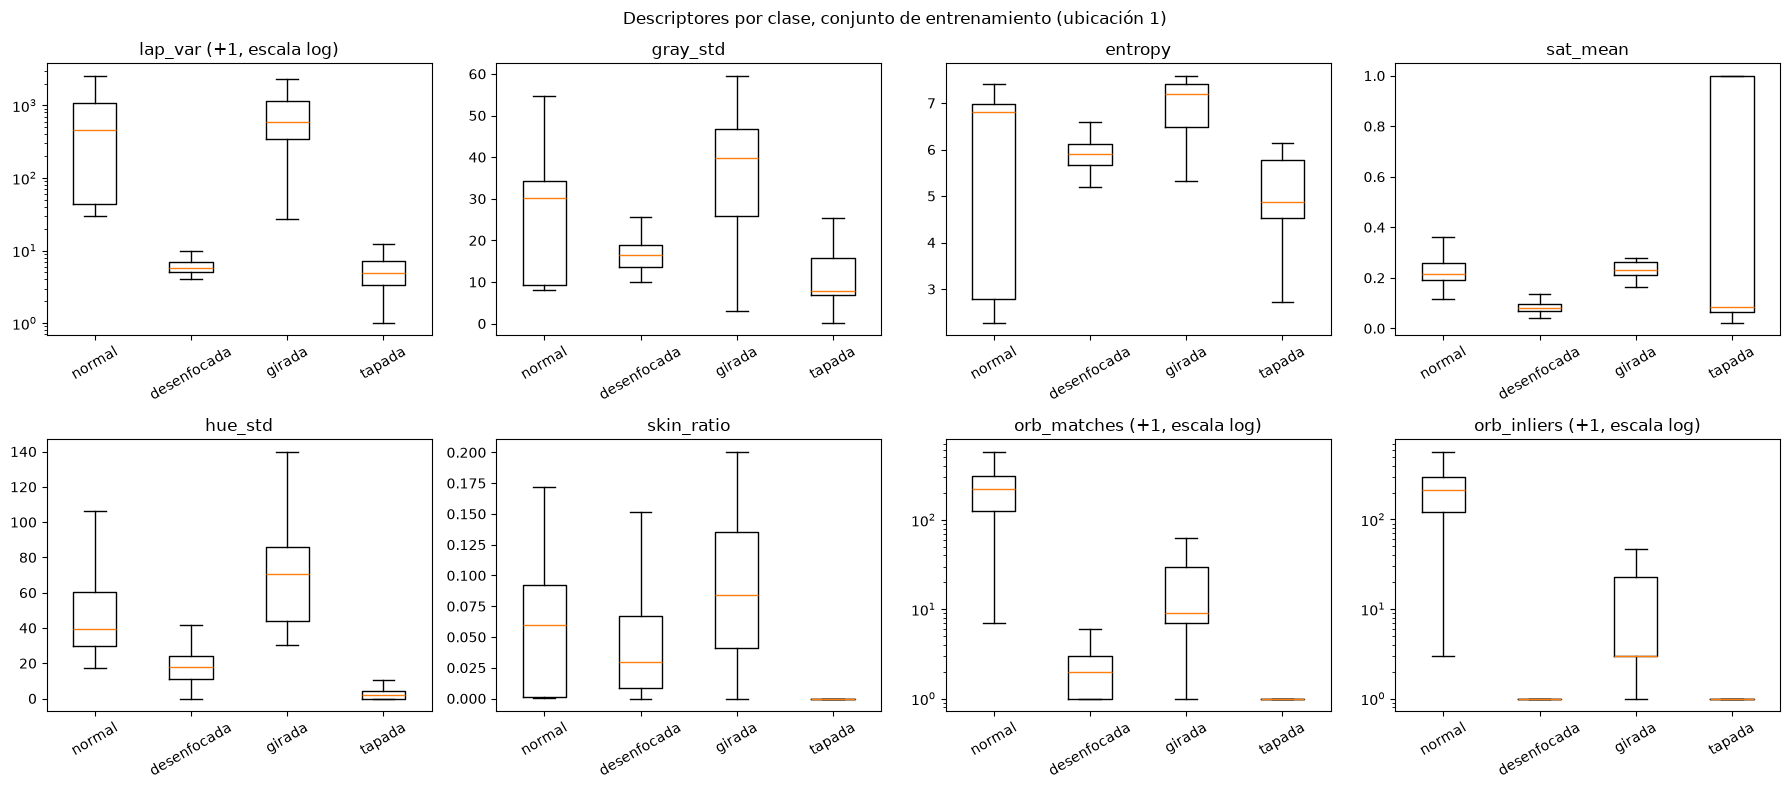

In [2]:
COLUMNS = ["lap_var", "gray_std", "entropy", "sat_mean", "hue_std", "skin_ratio", "orb_matches", "orb_inliers"]
LOG_SCALE = {"lap_var", "orb_matches", "orb_inliers"}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, column in zip(axes.ravel(), COLUMNS):
    values = [train.loc[train["label"] == label, column] + (1 if column in LOG_SCALE else 0) for label in ORDER]
    ax.boxplot(values, tick_labels=ORDER, showfliers=False)
    if column in LOG_SCALE:
        ax.set_yscale("log")
        ax.set_title(f"{column} (+1, escala log)")
    else:
        ax.set_title(column)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Descriptores por clase, conjunto de entrenamiento (ubicación 1)")
fig.tight_layout()
fig.savefig(ROOT / "results" / "figuras" / "descriptores_por_clase.png", dpi=120)
plt.show()

In [3]:
pd.set_option("display.width", 200)
summary = train.groupby("label")[COLUMNS].quantile([0.1, 0.5, 0.9]).round(2)
summary.loc[ORDER]

lap_var  gray_std  entropy  sat_mean  hue_std  skin_ratio  orb_matches  orb_inliers
label                                                                                               
normal      0.1    37.49      8.85     2.41      0.18    24.10        0.00         76.0         69.0
            0.5   453.28     30.29     6.81      0.21    39.37        0.06        220.0        212.0
            0.9  1319.59     38.75     7.11      0.35    79.94        0.11        379.0        376.2
desenfocada 0.1     3.73     10.96     5.30      0.06     7.01        0.00          0.0          0.0
            0.5     4.81     16.51     5.91      0.08    17.99        0.03          1.0          0.0
            0.9     7.06     21.13     6.26      0.12    43.04        0.10          5.0          0.0
girada      0.1    41.04      9.00     3.89      0.17    32.87        0.00          2.3          0.0
            0.5   585.35     39.91     7.20      0.23    70.33        0.08          8.0          2.0
            0.9  2258.04     52.03     7.43      0.46   100.35        0.18         57.7         53.7
tapada      0.1     1.01      3.58     1.49      0.06     0.00        0.00          0.0          0.0
            0.5     3.84      7.93     4.86      0.08     1.81        0.00          0.0          0.0
            0.9     6.57     17.30     5.96      1.00    11.32        0.00          0.0          0.0

## Qué muestran los datos

1. **Normal frente a cualquier sabotaje: `orb_matches`.** Las normales coinciden con sus referencias (mediana 220,
   percentil 10 = 76). Las desenfocadas y tapadas casi no tienen coincidencias (mediana 1 y 0) y las giradas pocas
   (mediana 8, percentil 90 = 58), porque la cámara apunta a otra escena.
2. **Desenfocada y tapada frente a girada: `lap_var`.** Desenfocadas y tapadas no tienen bordes nítidos (percentil
   90 por debajo de 7), mientras que las giradas son nítidas (percentil 10 = 41).
3. **Tapada frente a desenfocada: color y contraste.** Una tapa muestra un solo color: la dispersión del matiz
   (`hue_std`) de las tapadas tiene mediana 1,8° frente a 18° en las desenfocadas, y su contraste (`gray_std`) es
   la mitad.
4. **Lo que NO funciona:** el contraste (`gray_std`) no separa una tapada de una normal nocturna, porque de noche
   la escena también es oscura y de poco contraste (percentil 10 de las normales = 8,9, igual que la mediana de las
   tapadas). Por eso la decisión normal/sabotaje usa ORB y no el brillo: esto será clave en la defensa ante cambios
   de luz.